# Neural PDE Exercises · 02
## Collocation and an unseen residual

**Course section:** Strong-form PINNs. **Time:** 35–50 minutes.
This notebook is self-contained: select **Restart Kernel and Run All Cells** in a
fresh Python 3.11+ kernel. CPU / float64; the supplied run is a working baseline.

[All practical exercises](README.md) · [Laboratory guide](../NOTEBOOK_README.md) ·
[Related laboratory](../Neural_PDE_02_poisson_and_limits.ipynb)

**How to work:** predict the outcome, run the baseline, then edit the marked
settings and rerun all cells. Keep a small results table and answer the reflection
questions. Use the same seed and training budget when comparing methods.

**Notation:** $u$ is the reference state, $u_\theta$ the neural state,
$r_\theta=\mathcal L u_\theta-f$, $\widehat{\mathcal J}$ a sampled loss,
and $\mathcal E$ an energy. Reference values are used for checking errors after
training, except when observations are explicitly supplied.

## 1 · Predict before computing

Train a hard-boundary PINN for $-u''=\pi^2\sin(\pi x)$ using
$\widehat{\mathcal J}=n^{-1}\sum_j|r_\theta(x_j)/\pi^2|^2$.
This is a numerical approximation to a continuous loss. A small training loss
only checks the residual at the selected points.

**Predict:** is doubling the number of collocation points guaranteed to improve
solution error under a fixed optimization budget?

In [1]:
import copy
import math
import time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import torch
from torch import nn

SEED = 7
torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
palette = {"navy": "#10243A", "teal": "#00A6A6", "orange": "#F28C45",
           "pink": "#DC4778", "blue": "#4878D0", "ink": "#183449", "muted": "#63788A"}
plt.rcParams.update({
    "figure.facecolor": "#F7FAFC", "axes.facecolor": "#F7FAFC",
    "axes.edgecolor": "#CAD6DF", "axes.labelcolor": palette["ink"],
    "text.color": palette["ink"], "xtick.color": palette["muted"],
    "ytick.color": palette["muted"], "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#DCE5EB", "grid.alpha": 0.65,
    "lines.linewidth": 2.3, "figure.dpi": 100, "legend.frameon": False,
    "axes.prop_cycle": matplotlib.cycler(color=[palette[k] for k in
                                 ["teal", "orange", "pink", "blue", "navy"]]),
})

def network(width=20, activation=nn.Tanh):
    return nn.Sequential(nn.Linear(1, width), activation(),
                         nn.Linear(width, width), activation(), nn.Linear(width, 1))

class State(nn.Module):
    def __init__(self, initial, hard=True):
        super().__init__()
        self.net, self.hard = copy.deepcopy(initial), hard
    def forward(self, x):
        raw = self.net(x)
        return x*(1-x)*raw if self.hard else raw

def derivative(value, x):
    return torch.autograd.grad(value.sum(), x, create_graph=True)[0]

def forcing(x):
    return math.pi**2 * torch.sin(math.pi*x)

def residual(model, points):
    x = points.detach().clone().requires_grad_(True)
    u = model(x)
    return -derivative(derivative(u, x), x) - forcing(x)

def train(model, objective, steps=500, lr=0.004):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    started = time.perf_counter()
    for step in range(steps):
        optimizer.zero_grad(set_to_none=True)
        loss = objective(model)
        loss.backward()
        optimizer.step()
        history.append(float(loss.detach()))
    assert np.isfinite(history).all(), "The optimizer produced a non-finite objective."
    return np.asarray(history), time.perf_counter()-started

# This independent grid is never passed to a training objective.
check_x = torch.linspace(0, 1, 503).reshape(-1, 1)
check_u = torch.sin(math.pi*check_x).numpy().ravel()
boundary_x = torch.tensor([[0.0], [1.0]])

def diagnostics(model):
    with torch.no_grad():
        prediction = model(check_x).numpy().ravel()
        boundary_error = float(model(boundary_x).abs().max())
    scaled_residual = residual(model, check_x).detach().numpy().ravel()/math.pi**2
    relative_l2 = np.linalg.norm(prediction-check_u)/np.linalg.norm(check_u)
    return {"prediction": prediction, "relative_l2": float(relative_l2),
            "residual_rms": float(np.sqrt(np.mean(scaled_residual**2))),
            "boundary_max": boundary_error}

print(f"CPU / float64 / seed {SEED} / PyTorch {torch.__version__}")

CPU / float64 / seed 7 / PyTorch 2.10.0


n=  8 | training residual RMS 1.407e-03 | validation residual RMS 1.350e-02 | relative L2 6.773e-04


n= 32 | training residual RMS 2.350e-03 | validation residual RMS 3.520e-03 | relative L2 8.590e-05


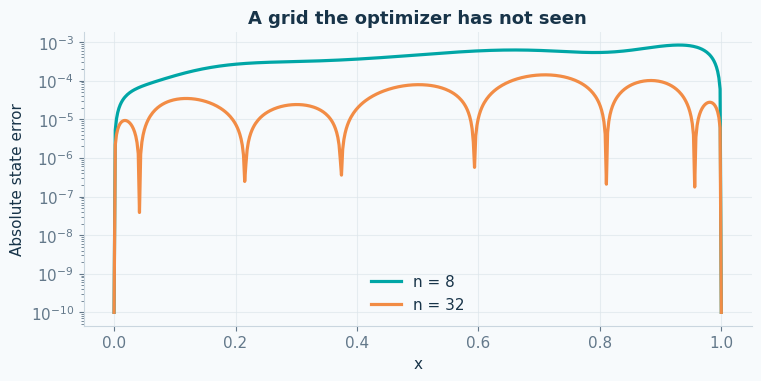

In [2]:
# EDIT HERE: add counts, change the sampler, or increase the common budget.
COUNTS = [8, 32]
SAMPLER = "uniform"             # "uniform" or "random"
STEPS = 500
assert SAMPLER in {"uniform", "random"}
initial = network()
reports, train_residuals = {}, {}
for count in COUNTS:
    if SAMPLER == "uniform":
        points = torch.linspace(0, 1, count+2)[1:-1].reshape(-1, 1)
    else:
        points = torch.tensor(rng.uniform(0, 1, (count, 1)))
    model = State(initial)
    history, seconds = train(model, lambda m: (residual(m, points)/math.pi**2).square().mean(), STEPS)
    reports[count] = diagnostics(model)
    train_residuals[count] = float((residual(model, points)/math.pi**2).square().mean().sqrt().detach())
    report = reports[count]
    print(f"n={count:3d} | training residual RMS {train_residuals[count]:.3e} | "
          f"validation residual RMS {report['residual_rms']:.3e} | "
          f"relative L2 {report['relative_l2']:.3e}")
fig, ax = plt.subplots(figsize=(7.5, 3.7), layout="constrained")
for count, report in reports.items():
    ax.semilogy(check_x, np.maximum(np.abs(report["prediction"]-check_u), 1e-10), label=f"n = {count}")
ax.set(title="A grid the optimizer has not seen", xlabel="x", ylabel="Absolute state error")
ax.grid(); ax.legend(); plt.show()

## 2 · Construct a blind spot

Set $x_j=j/(n+1)$ and consider the explicit candidate
$$v(x)=\sin(\pi x)+\varepsilon\sin((n+1)\pi x).$$
Both terms vanish at the boundary. The added mode's residual vanishes at every
training point, although its continuous residual is nonzero. This candidate is
constructed analytically to expose a sampling limitation; it is not a learned network.

Constructed candidate training residual RMS: 4.007e-15
Constructed candidate fresh residual RMS:    4.577e+00
Exact relative L2 state error: 0.080


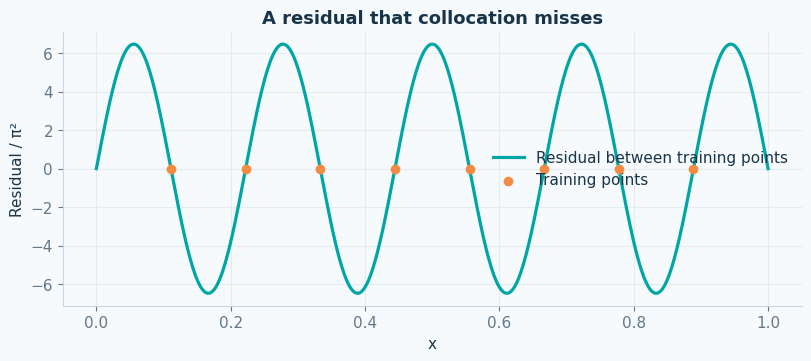

In [3]:
# EDIT HERE: the candidate is coupled to this particular uniform training grid.
ALIAS_COUNT = 8
AMPLITUDE = 0.08
alias_x = np.arange(1, ALIAS_COUNT+1)/(ALIAS_COUNT+1)
frequency = ALIAS_COUNT+1
fresh_x = check_x.numpy().ravel()
scaled_train_r = AMPLITUDE*frequency**2*np.sin(frequency*np.pi*alias_x)
scaled_fresh_r = AMPLITUDE*frequency**2*np.sin(frequency*np.pi*fresh_x)
print(f"Constructed candidate training residual RMS: {np.sqrt(np.mean(scaled_train_r**2)):.3e}")
print(f"Constructed candidate fresh residual RMS:    {np.sqrt(np.mean(scaled_fresh_r**2)):.3e}")
print(f"Exact relative L2 state error: {abs(AMPLITUDE):.3f}")
assert np.max(np.abs(scaled_train_r)) < 1e-10
fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
ax.plot(fresh_x, scaled_fresh_r, label="Residual between training points")
ax.scatter(alias_x, scaled_train_r, color=palette["orange"], zorder=3, label="Training points")
ax.set(title="A residual that collocation misses", xlabel="x", ylabel="Residual / π²")
ax.grid(); ax.legend(); plt.show()

## 3 · Your experiment and reflection

1. Compare uniform and random sampling at three collocation counts. Repeat with
   three seeds. Report both training and independent residual RMS, plus state error.
2. Evaluate the constructed candidate on newly drawn random points. Explain why
   changing the evaluation points detects this particular blind spot.
3. Keep the constructed state-error amplitude fixed while increasing `ALIAS_COUNT`.
   Explain the different scaling of state error and second-derivative residual.

**Hint:** the second derivative multiplies a sine mode by the square of its
frequency. Random points reduce this deliberate aliasing; a finite random sample
still cannot certify every possible function.

**Deliverable:** a comparison table, the blind-spot plot, and a paragraph separating
approximation error, optimization error, and sampling error in a PINN experiment.